# GGA 990 — Assignment 1: Health Facility Accessibility in Bayelsa State
**Student:** Osaigbovo Onaiwu-Nzegwu (41269) · **Lecturer:** Dr. Jude A. Adeleke · ISSE, AUST Abuja

Day 1: Practical Assignment for **Bayelsa State** and extends it to LGA level.

## Step 0: Libraries

In [1]:
!pip install mapclassify --quiet

import time
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from shapely.geometry import Point, LineString

## Step 1: Load the Bayelsa State boundary (geoBoundaries ADM1)

EPSG:4326 37
Bayelsa extent (lon/lat): [5.375 4.27  6.607 5.381]


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

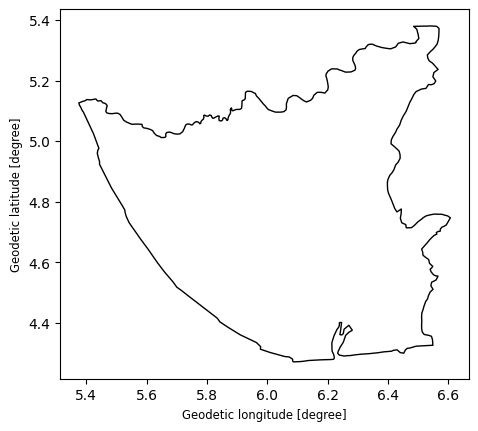

In [2]:
# Ask geoBoundaries for Nigeria's state boundaries, then read them into a GeoDataFrame
meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/NGA/ADM1/", timeout=120).json()
states = gpd.read_file(meta["gjDownloadURL"])
print(states.crs, len(states))   # EPSG:4326, 37 (36 states + FCT)

# Keep only the row whose name contains "Bayelsa"
bayelsa = states[states["shapeName"].str.contains("Bayelsa", case=False)].reset_index(drop=True)
print("Bayelsa extent (lon/lat):", bayelsa.total_bounds.round(3))   # note: west edge is about 5.38°E
bayelsa.plot(edgecolor="black", facecolor="none")

## Step 2: Download hospitals, clinics and major roads from OpenStreetMap (Overpass API)

* Facilities use `nwr` (nodes, ways **and** relations), so hospitals mapped as building outlines are included. `out center` returns one point per building.
* Roads are downloaded for the Bayelsa bounding box plus a ~10 km margin. This means facilities near the state border are measured to the nearest major road even if that road is just across the border in Rivers or Delta State (avoiding an edge effect).

In [4]:
OVERPASS_URLS = ["https://overpass-api.de/api/interpreter",
                 "https://overpass.kumi.systems/api/interpreter"]   # backup mirror
HEADERS = {"User-Agent": "GGA990-Assignment1/1.0 (student coursework)"}

w, s, e, n = bayelsa.total_bounds
margin = 0.1   # degrees, about 11 km
bbox = f"{s - margin},{w - margin},{n + margin},{e + margin}"   # Overpass order: south,west,north,east

query = f"""
[out:json][timeout:180];
area["name"="Bayelsa"]["admin_level"="4"]->.st;
nwr["amenity"~"^(hospital|clinic)$"](area.st);
out center tags;
way["highway"~"^(motorway|trunk|primary)(_link)?$"]({bbox});
out geom tags;
"""


def run_overpass(query):
    """Try each Overpass server in turn; stop with a clear error if all fail."""
    for url in OVERPASS_URLS:
        for attempt in range(2):
            try:
                r = requests.post(url, data={"data": query}, headers=HEADERS, timeout=200)
                r.raise_for_status()
                return r.json()
            except Exception as err:
                print(f"{url} attempt {attempt + 1} failed: {err}")
                time.sleep(10)
    raise RuntimeError("All Overpass servers failed - wait a minute and rerun this cell.")


data = run_overpass(query)
print("OSM data as of:", data["osm3s"]["timestamp_osm_base"])

health_list, roads_list = [], []
for el in data["elements"]:
    tags = el.get("tags", {})
    if tags.get("amenity") in ("hospital", "clinic"):
        # nodes carry lat/lon directly; ways and relations carry a 'center'
        lon = el["lon"] if el["type"] == "node" else el["center"]["lon"]
        lat = el["lat"] if el["type"] == "node" else el["center"]["lat"]
        health_list.append({"name": tags.get("name", "Unnamed"),
                            "amenity": tags["amenity"],
                            "osm_type": el["type"],
                            "geometry": Point(lon, lat)})
    elif "highway" in tags and "geometry" in el:
        coords = [(p["lon"], p["lat"]) for p in el["geometry"]]
        if len(coords) >= 2:
            roads_list.append({"highway": tags["highway"], "geometry": LineString(coords)})

health = gpd.GeoDataFrame(health_list, geometry="geometry", crs="EPSG:4326")
roads = gpd.GeoDataFrame(roads_list, geometry="geometry", crs="EPSG:4326")
print(f"{len(health)} facilities; {len(roads)} major-road segments")
print(health["osm_type"].value_counts())   # how many came from building outlines (way/relation)

OSM data as of: 2026-11-13T12:44:48Z
31 facilities; 215 major-road segments
osm_type
node        15
way         14
relation     2
Name: count, dtype: int64


## Step 3: Reproject to a projected CRS (metres)

In [5]:
# Convert everything from degrees to metres (UTM zone 32N) so distances and buffers are in metres
utm = "EPSG:32632"
bayelsa_u, health_u, roads_u = bayelsa.to_crs(utm), health.to_crs(utm), roads.to_crs(utm)


def drop_near_duplicates(gdf, tol_m=200):
    """Remove a facility mapped twice (e.g. as a point AND a building) with the same name within tol_m."""
    keep = []
    for name, grp in gdf.groupby("name"):
        if name == "Unnamed" or len(grp) == 1:
            keep.extend(grp.index)
            continue
        kept = []
        for i, row in grp.iterrows():
            if all(row.geometry.distance(p) > tol_m for p in kept):
                kept.append(row.geometry)
                keep.append(i)
    return gdf.loc[sorted(keep)]


before = len(health_u)
health_u = drop_near_duplicates(health_u)
print(f"Removed {before - len(health_u)} duplicate facility records")
assert bayelsa_u.crs == health_u.crs == roads_u.crs

Removed 0 duplicate facility records


### Task 1: Projected CRS justification

**EPSG:32632 (WGS 84 / UTM zone 32N)** was chosen because most of Bayelsa State, including all its major roads and the mapped health facilities, lies east of 6°E within zone 32N, so distances and buffers can be measured accurately in metres; the state's western edge (about 5.4°E, parts of Ekeremor and Southern Ijaw) extends only about 0.6° into zone 31N, where the additional scale distortion is negligible for 5 km buffer analysis.

## Task 2: Facilities within 5 km of a major road (state level)

In [6]:
# Keep only facilities inside the Bayelsa boundary
health_bayelsa = gpd.clip(health_u, bayelsa_u).reset_index(drop=True)

# 5 km buffer around major roads, merged into one polygon
road_buf = gpd.GeoDataFrame(geometry=[roads_u.buffer(5000).union_all()], crs=utm)

# Flag each facility as inside / outside the buffer, then calculate the percentage
health_bayelsa["near_road"] = health_bayelsa.within(road_buf.geometry.iloc[0])
n_total = len(health_bayelsa)
n_near = int(health_bayelsa["near_road"].sum())
pct = 100 * n_near / n_total
print(f"{n_near} of {n_total} facilities ({pct:.1f}%) are within 5 km of a major road")
print(health_bayelsa["amenity"].value_counts())

24 of 31 facilities (77.4%) are within 5 km of a major road
amenity
hospital    19
clinic      12
Name: count, dtype: int64


## Task 4: Distance from each facility to the nearest major road

In [7]:
# For each facility, find the nearest major road and its distance
dist = gpd.sjoin_nearest(health_bayelsa, roads_u[["highway", "geometry"]], distance_col="dist_m")
dist = dist[~dist.index.duplicated()].drop(columns="index_right")   # remove ties (equidistant roads)
dist["dist_km"] = (dist["dist_m"] / 1000).round(2)
print(dist["dist_km"].describe().round(2))

# Five facilities furthest from a major road
top5 = (dist.sort_values("dist_m", ascending=False)
            .head(5)[["name", "amenity", "highway", "dist_km"]]
            .reset_index(drop=True))
top5.index = top5.index + 1
top5.index.name = "Rank"
top5

count    31.00
mean     11.11
std      24.58
min       0.01
25%       0.60
50%       0.98
75%       3.48
max      82.01
Name: dist_km, dtype: float64


,name,amenity,highway,dist_km
Rank,,,,
1,Unnamed,hospital,primary,82.01
2,Unnamed,hospital,primary,82.01
3,Unnamed,hospital,primary,81.95
4,Ologoama Health Centre,hospital,primary,31.86
5,"Primary Health Centre, Toru-Ebeni",clinic,primary,24.13


## Interactive map of facilities, roads and the 5 km buffer

In [8]:
TILES = "https://{s}.tile.openstreetmap.fr/hot/{z}/{x}/{y}.png"
ATTR = ("&copy; <a href='https://www.openstreetmap.org/copyright'>OpenStreetMap</a> contributors, "
        "tiles by <a href='https://hotosm.org/'>Humanitarian OpenStreetMap Team</a>")


def base_map():
    m = folium.Map(tiles=None)
    folium.TileLayer(TILES, attr=ATTR, name="OSM Humanitarian").add_to(m)
    w, s, e, n = bayelsa.total_bounds
    m.fit_bounds([[s, w], [n, e]])
    return m


# Distance classes are easier to read than a continuous scale dominated by one outlier
bins = [0, 1, 2, 5, 10, np.inf]
labels = ["< 1 km", "1-2 km", "2-5 km", "5-10 km", "> 10 km"]
dist["dist_class"] = pd.cut(dist["dist_km"], bins=bins, labels=labels, right=False).astype(str)

m = base_map()
bayelsa.explore(m=m, style_kwds={"fill": False, "color": "black", "weight": 2}, name="Bayelsa boundary")
road_buf.to_crs(4326).explore(m=m, color="orange", style_kwds={"fillOpacity": 0.25}, name="5 km road buffer")
roads.explore(m=m, color="#555555", style_kwds={"weight": 2}, name="Major roads")
dist.to_crs(4326).explore(
    m=m, column="dist_class", categorical=True, categories=labels,
    cmap=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"],
    marker_kwds={"radius": 6}, style_kwds={"color": "black", "weight": 1, "fillOpacity": 0.9},
    tooltip=["name", "amenity", "dist_km"],
    tooltip_kwds={"aliases": ["Facility", "Type", "Distance to major road (km)"]},
    legend_kwds={"caption": "Distance to nearest major road"},
    name="Health facilities")
folium.LayerControl().add_to(m)

m.save("Bayelsa_health_access.html")
dist.to_file("Bayelsa_health_access.gpkg", layer="facilities", driver="GPKG")
m

## Task 3: LGA-level analysis (geoBoundaries ADM2)

The national LGA layer and the state layer do not line up exactly along borders, so clipping by the state boundary also picks up thin slivers of neighbouring LGAs in Rivers and Delta States. Instead, an LGA is kept only if its **interior point** falls inside Bayelsa. This keeps the eight Bayelsa LGAs and nothing else.

In [9]:
lgas_meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/NGA/ADM2/", timeout=120).json()
lgas_u = gpd.read_file(lgas_meta["gjDownloadURL"]).to_crs(utm)

inside = lgas_u.representative_point().within(bayelsa_u.union_all())
bayelsa_lgas_u = lgas_u[inside][["shapeID", "shapeName", "geometry"]].reset_index(drop=True)
bayelsa_lgas_u = bayelsa_lgas_u.rename(columns={"shapeName": "LGA"})

print(f"{len(bayelsa_lgas_u)} LGAs in Bayelsa:", sorted(bayelsa_lgas_u["LGA"]))
if len(bayelsa_lgas_u) != 8:
    print("Warning: Bayelsa has 8 LGAs - check the list above.")

8 LGAs in Bayelsa: ['Brass', 'Ekeremor', 'Kolokuma/Opokuma', 'Nembe', 'Ogbia', 'Sagbama', 'Southern Ijaw', 'Yenegoa']


In [10]:
# Assign each facility to the LGA it falls within
fac_lga = gpd.sjoin(health_bayelsa, bayelsa_lgas_u[["LGA", "geometry"]], predicate="within", how="left")
unassigned = fac_lga["LGA"].isna().sum()
if unassigned:
    print(f"{unassigned} facilities fell on/between LGA boundaries and were not assigned")

# Count facilities and those within 5 km per LGA
stats = (fac_lga.dropna(subset=["LGA"])
                .groupby("LGA")
                .agg(total_facilities=("near_road", "size"),
                     near_facilities=("near_road", "sum")))

lga_stats = bayelsa_lgas_u.merge(stats, on="LGA", how="left")
lga_stats[["total_facilities", "near_facilities"]] = (
    lga_stats[["total_facilities", "near_facilities"]].fillna(0).astype(int))

# LGAs with no mapped facility get NaN (no data), NOT 0% - a 0% would wrongly suggest poor access
lga_stats["pct_accessible"] = np.where(
    lga_stats["total_facilities"] > 0,
    (100 * lga_stats["near_facilities"] / lga_stats["total_facilities"]).round(1),
    np.nan)

lga_stats[["LGA", "total_facilities", "near_facilities", "pct_accessible"]].sort_values("LGA")

,LGA,total_facilities,near_facilities,pct_accessible
3,Brass,0,0,NaN
0,Ekeremor,0,0,NaN
6,Kolokuma/Opokuma,0,0,NaN
2,Nembe,1,0,0.0
4,Ogbia,1,0,0.0
7,Sagbama,2,0,0.0
1,Southern Ijaw,3,0,0.0
5,Yenegoa,24,24,100.0


In [11]:
# Choropleth of % facilities within 5 km of a major road, by LGA
m_lga = base_map()
lga_stats.to_crs(4326).explore(
    m=m_lga, column="pct_accessible", cmap="RdYlGn", vmin=0, vmax=100,
    legend=True, legend_kwds={"caption": "% of facilities within 5 km of a major road"},
    missing_kwds={"color": "lightgrey", "label": "No facilities in OSM"},
    style_kwds={"fillOpacity": 0.7, "color": "black", "weight": 1},
    tooltip=["LGA", "total_facilities", "near_facilities", "pct_accessible"],
    tooltip_kwds={"aliases": ["LGA", "Facilities", "Within 5 km", "% within 5 km"]},
    name="LGA accessibility")
health_bayelsa.to_crs(4326).explore(
    m=m_lga, color="black", marker_kwds={"radius": 3}, tooltip=["name", "amenity"], name="Facilities")
folium.LayerControl().add_to(m_lga)

m_lga.save("bayelsa_LGA_health_access.html")
m_lga

In [12]:
# Numbers for the write-up below
print(f"State: {n_near}/{n_total} facilities ({pct:.1f}%) within 5 km of a major road")
print(f"Hospitals: {(dist.amenity == 'hospital').sum()}, clinics: {(dist.amenity == 'clinic').sum()}")
print(f"Median distance: {dist.dist_km.median():.2f} km; maximum: {dist.dist_km.max():.2f} km")
no_data = lga_stats.loc[lga_stats.total_facilities == 0, "LGA"].tolist()
print(f"LGAs with no OSM facility ({len(no_data)}): {no_data}")
print(lga_stats[["LGA", "total_facilities", "pct_accessible"]].to_string(index=False))

State: 24/31 facilities (77.4%) within 5 km of a major road
Hospitals: 19, clinics: 12
Median distance: 0.98 km; maximum: 82.01 km
LGAs with no OSM facility (3): ['Ekeremor', 'Brass', 'Kolokuma/Opokuma']
             LGA  total_facilities  pct_accessible
        Ekeremor                 0             NaN
   Southern Ijaw                 3             0.0
           Nembe                 1             0.0
           Brass                 0             NaN
           Ogbia                 1             0.0
         Yenegoa                24           100.0
Kolokuma/Opokuma                 0             NaN
         Sagbama                 2             0.0


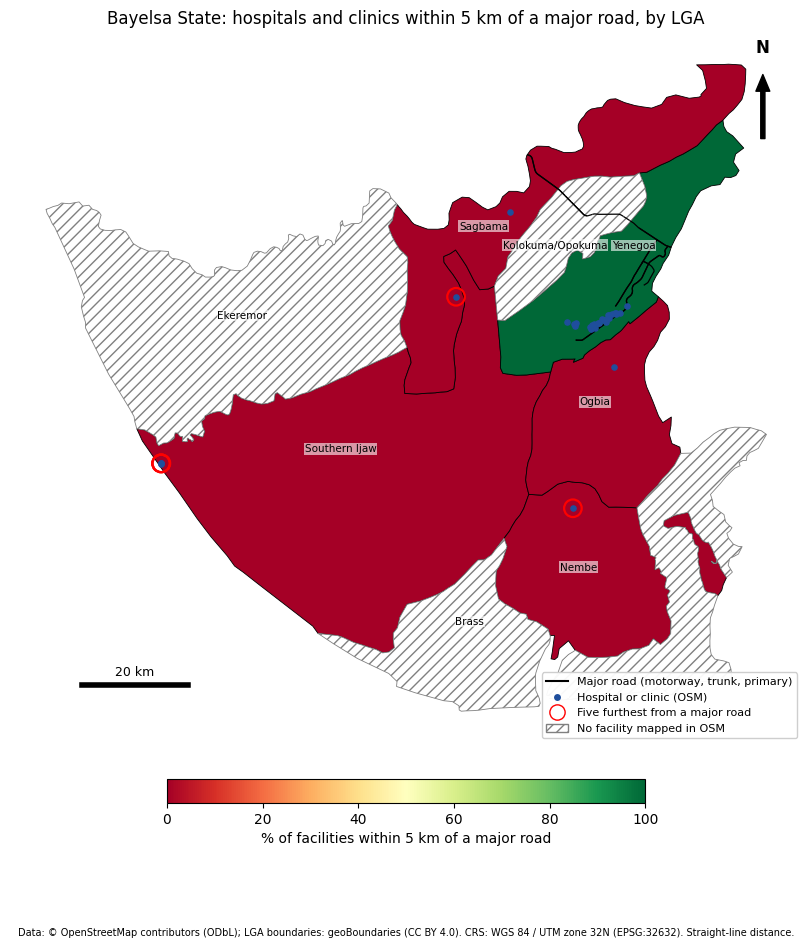

In [13]:
# [Added for portfolio] Static LGA choropleth saved as PNG (adapted from the lecturer's Kaduna worked solution)
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(9, 9.5))
lga_stats.plot(column="pct_accessible", cmap="RdYlGn", vmin=0, vmax=100, ax=ax,
               edgecolor="black", linewidth=0.6, legend=True,
               legend_kwds={"label": "% of facilities within 5 km of a major road",
                            "shrink": 0.55, "orientation": "horizontal", "pad": 0.04},
               missing_kwds={"color": "white", "hatch": "///", "edgecolor": "grey"})
roads_u.clip(bayelsa_u).plot(ax=ax, color="black", linewidth=0.9)
dist.plot(ax=ax, color="#1f4e9c", markersize=14, zorder=3)
furthest5 = dist.nlargest(5, "dist_m")
furthest5.plot(ax=ax, facecolor="none", edgecolor="red", markersize=160, linewidth=1.6, zorder=4)

for _, r in lga_stats.iterrows():                       # LGA names
    p = r.geometry.representative_point()
    ax.annotate(r["LGA"], (p.x, p.y), ha="center", fontsize=7.5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.6, pad=0.5))

xmin, ymin, xmax, ymax = bayelsa_u.total_bounds          # 20 km scale bar (metres, UTM 32N)
x0, y0 = xmin + 0.05 * (xmax - xmin), ymin + 0.04 * (ymax - ymin)
ax.plot([x0, x0 + 20000], [y0, y0], color="black", linewidth=4)
ax.text(x0 + 10000, y0 + 0.015 * (ymax - ymin), "20 km", ha="center", fontsize=9)
ax.annotate("", xy=(0.95, 0.94), xytext=(0.95, 0.85), xycoords="axes fraction",
            arrowprops=dict(facecolor="black", width=3, headwidth=10))
ax.text(0.95, 0.965, "N", transform=ax.transAxes, ha="center", va="bottom", fontsize=12, fontweight="bold")

ax.legend(handles=[Line2D([0], [0], color="black", lw=1.5, label="Major road (motorway, trunk, primary)"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f4e9c", markersize=6, label="Hospital or clinic (OSM)"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor="none", markeredgecolor="red", markersize=11, label="Five furthest from a major road"),
                   Patch(facecolor="white", edgecolor="grey", hatch="///", label="No facility mapped in OSM")],
          loc="lower right", fontsize=8, framealpha=0.95)
ax.set_title("Bayelsa State: hospitals and clinics within 5 km of a major road, by LGA", fontsize=12)
ax.set_axis_off()
fig.text(0.5, 0.01, "Data: © OpenStreetMap contributors (ODbL); LGA boundaries: geoBoundaries (CC BY 4.0). "
         "CRS: WGS 84 / UTM zone 32N (EPSG:32632). Straight-line distance.", ha="center", fontsize=7)
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.savefig("bayelsa_lga_choropleth.png", dpi=200)
plt.show()


## Task 4: Five facilities furthest from a major road


| Rank | Facility | Type | Nearest road class | Distance (km) |
|---|---|---|---|---|
| 1 | Unnamed | hospital | primary | 82.01 |
| 2 | Unnamed | hospital | primary | 82.01 |
| 3 | Unnamed | hospital | primary | 81.95 |
| 4 | Ologoama Health Centre | hospital | primary | 31.86 |
| 5 | Primary Health Centre, Toru-Ebeni | clinic | primary | 24.13 |

*Note: the three unnamed hospital records have almost identical distances, which suggests they may be a single site mapped more than once in OpenStreetMap. Unnamed records were not removed by the duplicate check, which matches on name.*

## Task 5: Interpretation and discussion (~300 words)


Using OpenStreetMap data retrieved in November 2026, 31 health facilities (19 hospitals and 12 clinics) were mapped in Bayelsa State, of which 24 (77.4%) lie within 5 km of a motorway, trunk or primary road. The median straight-line distance to a major road is 0.98 km, but the distribution is strongly skewed: three unnamed hospital records lie about 82 km from the nearest major road, Ologoama Health Centre lies 31.9 km away and the Primary Health Centre at Toru-Ebeni 24.1 km away, far beyond the 5 km threshold. These facilities depend largely on water transport.


At LGA level, the pattern is one of sharp concentration rather than even coverage. Yenagoa LGA holds 24 of the 31 mapped facilities, and all 24 fall within the buffer (100%), reflecting the state capital's position on the main road corridor. Every facility outside Yenagoa lies beyond 5 km of a major road: Southern Ijaw (3 facilities), Sagbama (2), Nembe (1) and Ogbia (1) all score 0%. Ekeremor, Brass and Kolokuma/Opokuma have no hospital or clinic recorded in OpenStreetMap at all, and appear as "no data" on the choropleth. This should not be read as an absence of health services; it shows that the riverine and coastal LGAs, where communities are linked mainly by creeks and rivers rather than roads, are also the least completely mapped. The state-level figure of 77.4% is therefore driven almost entirely by well-mapped, road-connected Yenagoa and overstates accessibility for the state as a whole.

**Limitations**

1. **Incompleteness of OpenStreetMap.** Volunteer mapping in Bayelsa is concentrated in Yenagoa; many primary health centres in riverine LGAs are not mapped, some records are unnamed or possibly duplicated, and facilities tagged differently (e.g. `healthcare=centre`) were not captured by the `amenity=hospital|clinic` query. An official register such as the Nigeria Health Facility Registry or GRID3 data would give a far more complete picture.
2. **Straight-line distance ignores the real travel network.** A Euclidean buffer treats creeks and mangrove swamps as if they could be crossed directly, and waterways, the main transport routes in much of the state, are not counted at all. A travel-time analysis including boat routes would represent access more realistically.